In [1]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

np.random.seed(22)

measurements = ["height", "weight", "age", "temperature", "pressure"]
print(measurements)

['height', 'weight', 'age', 'temperature', 'pressure']


In [2]:
n = 400
male = np.random.rand(n) < 0.5          

size = np.random.randn(n) + 0.7 * male  
build = np.random.randn(n)
leg_trait = np.random.randn(n)

height = 66 + 3.0*size + 0.8*leg_trait + np.random.randn(n)*0.8
arm_span = height + 0.5 + 0.6*size + np.random.randn(n)*1.0
leg_length = 0.45*height + 1.5*leg_trait + np.random.randn(n)*0.7
weight = 160 + 18*size + 20*build + np.random.randn(n)*6
shoe_size = 9 + 1.2*size + 0.3*leg_trait + np.random.randn(n)*0.4

df = pd.DataFrame({
    "height": height,
    "arm_span": arm_span,
    "leg_length": leg_length,
    "weight": weight,
    "shoe_size": shoe_size,
})
df["male"] = male

print(df.head())
print(df.describe().round(2))

      height   arm_span  leg_length      weight  shoe_size   male
0  66.578506  67.203671   28.336276  174.122199   9.139742   True
1  63.188004  61.699088   27.426045  138.797240   8.002273   True
2  67.545284  68.361154   30.575744  153.790557   9.761293   True
3  65.968573  64.179822   29.852727  152.914543   8.635717  False
4  67.304174  68.931223   27.381574  201.017043   9.679305   True
       height  arm_span  leg_length  weight  shoe_size
count  400.00    400.00      400.00  400.00     400.00
mean    66.99     67.68       30.06  165.91       9.41
std      3.38      4.08        2.47   30.04       1.36
min     57.65     56.07       22.17   91.41       4.85
25%     64.76     64.80       28.43  144.71       8.47
50%     67.06     67.90       30.08  164.68       9.41
75%     69.29     70.45       31.65  186.58      10.31
max     75.96     78.29       36.92  260.39      13.12


In [3]:
cols = ["height", "arm_span", "leg_length", "weight", "shoe_size"]

X = df[cols]
Z = (X - X.mean()) / X.std()

print(Z.mean().round(2))  
print(Z.std().round(2))    

height       -0.0
arm_span      0.0
leg_length    0.0
weight        0.0
shoe_size     0.0
dtype: float64
height        1.0
arm_span      1.0
leg_length    1.0
weight        1.0
shoe_size     1.0
dtype: float64


In [4]:
C = np.cov(Z.values, rowvar=False)
vals, vecs = np.linalg.eigh(C)          
idx = np.argsort(vals)[::-1]            
vals = vals[idx]
vecs = vecs[:, idx]

for j in range(vecs.shape[1]):
    k = np.argmax(np.abs(vecs[:, j]))
    if vecs[k, j] < 0:
        vecs[:, j] = -vecs[:, j]

print(C.round(2))
print(vals.round(3))
print(vecs.round(2))

[[1.   0.97 0.77 0.63 0.93]
 [0.97 1.   0.72 0.62 0.92]
 [0.77 0.72 1.   0.37 0.73]
 [0.63 0.62 0.37 1.   0.6 ]
 [0.93 0.92 0.73 0.6  1.  ]]
[3.959 0.646 0.283 0.085 0.026]
[[ 0.49 -0.06 -0.22 -0.32  0.77]
 [ 0.49 -0.03 -0.35 -0.5  -0.62]
 [ 0.41 -0.54  0.73  0.02 -0.08]
 [ 0.36  0.84  0.42  0.03 -0.03]
 [ 0.48 -0.06 -0.35  0.8  -0.08]]


In [5]:
share = vals / vals.sum()         
cum = np.cumsum(share)            

n_comp = np.argmax(cum >= 0.90) + 1  

print(share.round(3))
print(cum.round(3))
print("Components for 90%:", n_comp)

[0.792 0.129 0.057 0.017 0.005]
[0.792 0.921 0.978 0.995 1.   ]
Components for 90%: 2


In [6]:
scores = Z.values @ vecs[:, :2]        

df["PC1"] = scores[:, 0]
df["PC2"] = scores[:, 1]

print(df.groupby("male")[["PC1", "PC2"]].mean().round(2))

        PC1   PC2
male             
False -0.59 -0.02
True   0.62  0.02


In [7]:
rmse = []
theory = []

for k in range(1, 6):
    V = vecs[:, :k]                    
    scores_k = Z.values @ V           
    Z_hat = scores_k @ V.T             

    err = Z.values - Z_hat
    rmse.append(np.sqrt((err**2).mean()))

    dropped = vals[k:].sum()           
    theory.append(np.sqrt(dropped / 5 * (399 / 400)))

for k in range(5):
    print(k + 1, round(rmse[k], 4), round(theory[k], 4))

1 0.4557 0.4557
2 0.2806 0.2806
3 0.1489 0.1489
4 0.0724 0.0724
5 0.0 0.0


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# left: scree + cumulative
pcs = np.arange(1, 6)
ax[0].bar(pcs, share, color="steelblue", label="Variance share")
ax[0].plot(pcs, cum, "o-", color="darkorange", label="Cumulative")
ax[0].axhline(0.90, color="red", linestyle="--", label="90%")
ax[0].set_xlabel("Component")
ax[0].set_ylabel("Proportion of variance")
ax[0].set_xticks(pcs)
ax[0].set_ylim(0, 1.05)
ax[0].set_title("Scree plot")
ax[0].legend()

# right: PC1 vs PC2 by sex
m = df["male"].values
ax[1].scatter(df.loc[~m, "PC1"], df.loc[~m, "PC2"], c="crimson", alpha=0.6, s=15, label="Female")
ax[1].scatter(df.loc[m, "PC1"], df.loc[m, "PC2"], c="royalblue", alpha=0.6, s=15, label="Male")
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")
ax[1].set_title("People in PC space")
ax[1].legend()

plt.tight_layout()
plt.savefig("pca_plots.png", dpi=150)

In [9]:
rmse, theory = [], []
for k in range(1, 6):
    V = vecs[:, :k]
    Z_hat = (Z.values @ V) @ V.T
    rmse.append(np.sqrt(((Z.values - Z_hat)**2).mean()))
    theory.append(np.sqrt(vals[k:].sum() / 5 * (399 / 400)))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

x = np.arange(5); w = 0.38
ax[0].bar(x - w/2, vecs[:, 0], w, color="steelblue", label="PC1")
ax[0].bar(x + w/2, vecs[:, 1], w, color="darkorange", label="PC2")
ax[0].axhline(0, color="black", linewidth=0.8)
ax[0].set_xticks(x); ax[0].set_xticklabels(cols, rotation=20)
ax[0].set_ylabel("Loading"); ax[0].set_title("PC1 and PC2 loadings"); ax[0].legend()

ks = np.arange(1, 6)
ax[1].plot(ks, rmse, "o-", color="royalblue", label="Measured RMSE", markersize=9)
ax[1].plot(ks, theory, "x--", color="crimson", label="Theory", markersize=9)
ax[1].set_xticks(ks)
ax[1].set_xlabel("Components kept"); ax[1].set_ylabel("RMSE (std units)")
ax[1].set_title("Reconstruction error"); ax[1].legend()

plt.tight_layout()
plt.savefig("pca_loadings_error.png", dpi=150)

In [14]:
import json

n_comp = int(np.argmax(cum >= 0.90 - 1e-12) + 1)
grp = df.groupby("male")["PC1"].mean()

fig, ax = plt.subplots(2, 2, figsize=(12, 9))
pcs = np.arange(1, 6)

ax[0, 0].bar(pcs, share, color="steelblue", label="Variance share")
ax[0, 0].plot(pcs, cum, "o-", color="darkorange", label="Cumulative")
ax[0, 0].axhline(0.90, color="red", linestyle="--", label="90%")
ax[0, 0].set_xticks(pcs); ax[0, 0].set_ylim(0, 1.05)
ax[0, 0].set_xlabel("Component"); ax[0, 0].set_ylabel("Proportion of variance")
ax[0, 0].set_title("Scree plot"); ax[0, 0].legend()

m = df["male"].values
ax[0, 1].scatter(df.loc[~m, "PC1"], df.loc[~m, "PC2"], c="crimson", alpha=0.6, s=15, label="Female")
ax[0, 1].scatter(df.loc[m, "PC1"], df.loc[m, "PC2"], c="royalblue", alpha=0.6, s=15, label="Male")
ax[0, 1].set_xlabel("PC1"); ax[0, 1].set_ylabel("PC2")
ax[0, 1].set_title("People in PC space"); ax[0, 1].legend()

x = np.arange(5); w = 0.38
ax[1, 0].bar(x - w/2, vecs[:, 0], w, color="steelblue", label="PC1")
ax[1, 0].bar(x + w/2, vecs[:, 1], w, color="darkorange", label="PC2")
ax[1, 0].axhline(0, color="black", linewidth=0.8)
ax[1, 0].set_xticks(x); ax[1, 0].set_xticklabels(cols, rotation=20)
ax[1, 0].set_ylabel("Loading"); ax[1, 0].set_title("PC1 and PC2 loadings"); ax[1, 0].legend()

ax[1, 1].plot(pcs, rmse, "o-", color="royalblue", label="Measured RMSE", markersize=9)
ax[1, 1].plot(pcs, theory, "x--", color="crimson", label="Theory", markersize=9)
ax[1, 1].set_xticks(pcs)
ax[1, 1].set_xlabel("Components kept"); ax[1, 1].set_ylabel("RMSE (std units)")
ax[1, 1].set_title("Reconstruction error"); ax[1, 1].legend()

plt.tight_layout()
plt.savefig("chart.png", dpi=120)

summary = [
    f"PC1 explains {share[0]*100:.1f}% of the variance and PC2 explains {share[1]*100:.1f}%.",
    f"{n_comp} components reach 90% of the variance (cumulative {cum[n_comp-1]*100:.1f}%).",
    f"Mean PC1 is {grp[True]:.2f} for males and {grp[False]:.2f} for females.",
    f"RMSE with 1 component is {rmse[0]:.3f}; with 2 it is {rmse[1]:.3f}.",
    f"Largest difference between measured and theoretical RMSE is {max(abs(a-b) for a, b in zip(rmse, theory)):.1e}.",
]
for s in summary:
    print(s)

with open("results.json", "w") as f:
    json.dump({"summary": summary}, f, indent=2)

PC1 explains 79.2% of the variance and PC2 explains 12.9%.
2 components reach 90% of the variance (cumulative 92.1%).
Mean PC1 is 0.62 for males and -0.59 for females.
RMSE with 1 component is 0.456; with 2 it is 0.281.
Largest difference between measured and theoretical RMSE is 1.0e-15.


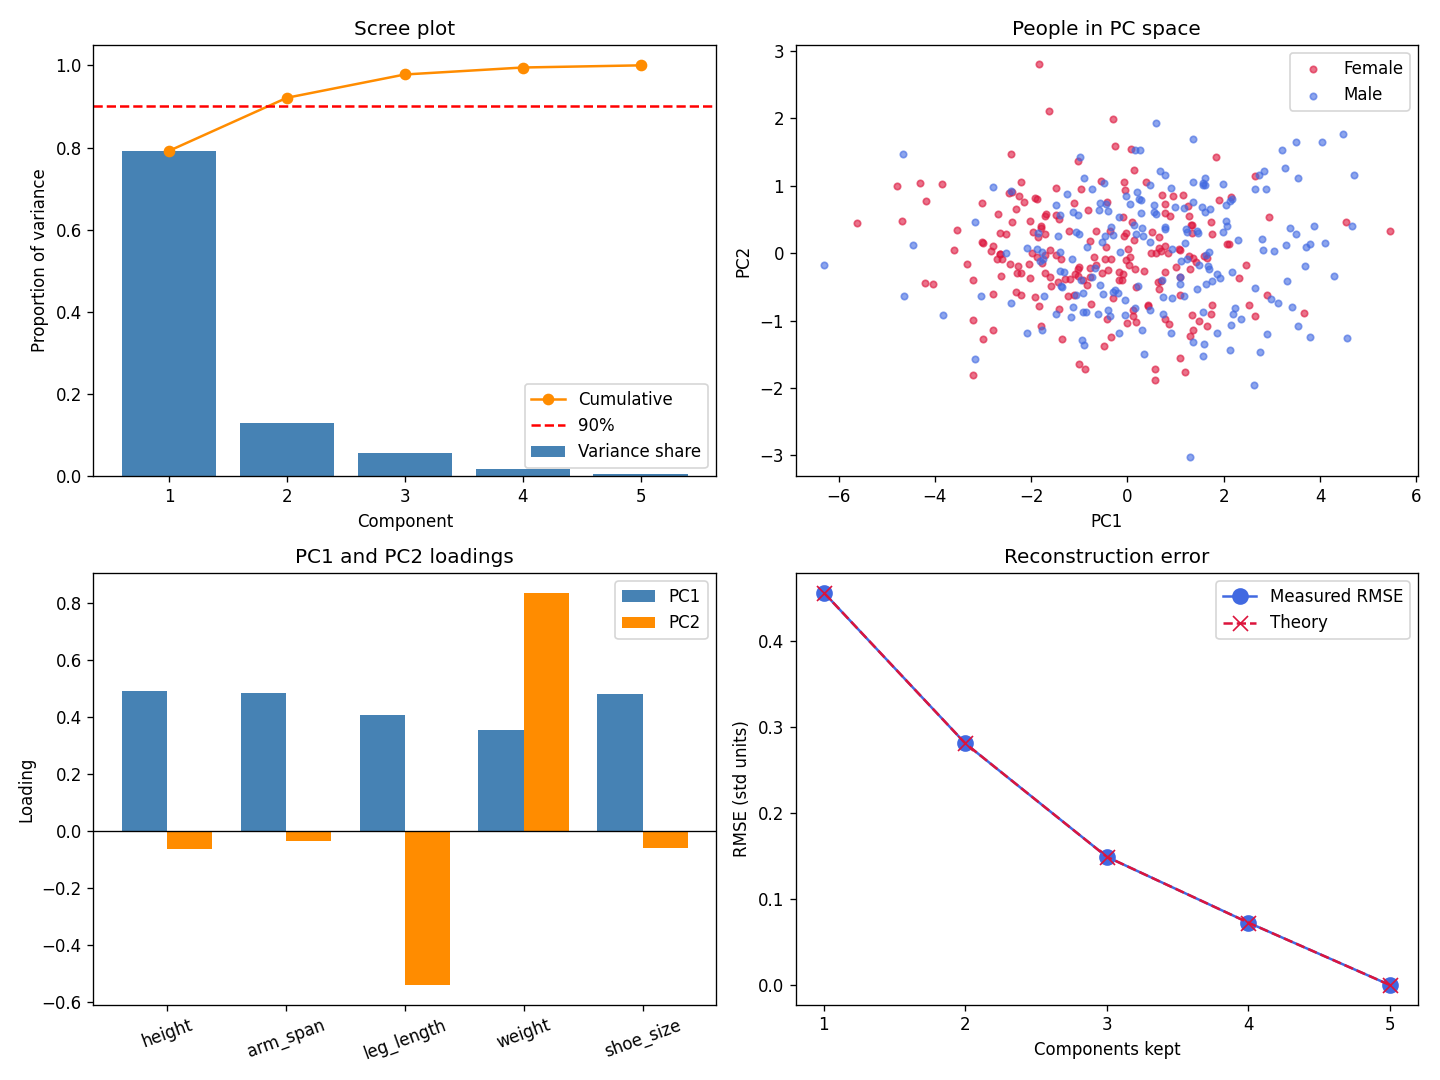

In [13]:
from IPython.display impor
t Image
Image("chart.png")